## Notebook de estudos do dataset [Alpaca Dataset for Image Classification](https://www.kaggle.com/datasets/sid4sal/alpaca-dataset-small/data), aplicando conceitos importantes de visão computacional com a ferramenta pytorch

Nessa aplicação, será usado a metodologia transfer learning, no qual será utilizado um modelo disponibilizado pela ResNet para fazer predições com as imagens disponibilizadas

### Imports

In [19]:
import time
import kagglehub
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shutil
import copy
from tqdm.auto import tqdm
import gc
import os
import json

from sklearn.metrics import classification_report,confusion_matrix,precision_score,recall_score, accuracy_score,f1_score
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torchvision.transforms import transforms
from torchvision.datasets.folder import ImageFolder
from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.model_selection import train_test_split

import onnxruntime as ort

### Leitura dos dados

In [2]:
path = kagglehub.dataset_download("sid4sal/alpaca-dataset-small")

print("Path to dataset files:", path)

In [3]:
pasta_destino = "dados_kaggle"
shutil.copytree(path,pasta_destino,dirs_exist_ok=True)

'dados_kaggle'

### Verificação de GPU

In [4]:
devices = [d for d in range(torch.cuda.device_count())]
device_names = [torch.cuda.get_device_name(d) for d in devices]
device_names

['NVIDIA GeForce RTX 3060']

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

### Funções Auxiliares

- O training_epoch auxiliará no treinamento do modelo
- As outras funções vão servir de base experimental para montar um pipeline de treino eficiente com os recursos de máquina disponíveis
- Outras funções são apenas para observação visual dos resultados

In [6]:
def training_epoch(model, loader, train:bool, device, criterion,optimizer):
    
    model.train() if train else model.eval()
    total_loss, total = 0.0,0
    all_preds, all_labels = [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            
            logits = model(x)
            loss = criterion(logits,y)
            
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            total += x.size(0)
            all_preds.extend(logits.argmax(1).cpu().tolist())
            all_labels.extend(y.cpu().tolist())
            
    return {
        "loss":      total_loss / total,
        "accuracy":  accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, pos_label=0, zero_division=0),
        "recall":    recall_score(all_labels, all_preds, pos_label=0, zero_division=0),
        "f1":        f1_score(all_labels, all_preds, pos_label=0, zero_division=0),
        "y_true":    all_labels,
        "y_pred":    all_preds,
    }

def plot_performance_summary(results_dict, title, xlabel, ylabel="Stable Time per Epoch (ms)"):
    """
    Generates a performance plot with annotations from a dictionary of results.

    Args:
        results_dict: A dictionary where keys are parameters and values are performance metrics.
        title: The title of the plot.
        xlabel: The label for the x-axis.
        ylabel: The label for the y-axis.
    """
    # Create a new dictionary to store only valid results
    valid_times = {k: v for k, v in results_dict.items() if v != float("inf")}

    # Check if there are any valid results to plot
    if not valid_times:
        # Print a message if no valid data is found
        print("No valid results to plot.")
        # Exit the function if there is no data
        return

    # Convert the time values from seconds to milliseconds
    valid_times_ms = {k: v * 1000 for k, v in valid_times.items()}

    # Create a new figure with a specified size
    plt.figure(figsize=(10, 5))

    # Plot the data points with a line and markers
    (line,) = plt.plot(
        list(valid_times_ms.keys()),
        list(valid_times_ms.values()),
        marker="o",
        linestyle="--",
        color="#237B94",
    )

    # Set the title and labels for the plot axes
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    # Set the x-axis ticks to match the keys in the dictionary
    plt.xticks(list(valid_times_ms.keys()))
    # Add a grid to the plot for better readability
    plt.grid(True)

    # Get the y-values to determine plot limits
    y_values = list(valid_times_ms.values())
    # Set the x-axis limits
    plt.xlim(left=0)
    # Set the y-axis limits with a 10% padding at the top
    plt.ylim(bottom=0, top=max(y_values) + max(y_values) * 0.1)

    # Get the color of the plotted line for annotations
    marker_color = line.get_color()
    # Calculate a vertical offset for the annotations
    vertical_offset = max(y_values) * 0.06

    # Iterate over the data points to add annotations
    for x, y in valid_times_ms.items():
        # Add a text annotation at each data point
        plt.text(
            x,
            y + vertical_offset,
            f"{y:.2f}",
            ha="center",
            color=marker_color,
        )

    # Display the plot
    plt.show()

def run_experiment(experiment_name, experiment_fcn, cases, trainset, device, rerun=False):
    
    folder_experiments = "./checkpoint_experiments"
    
    os.makedirs(folder_experiments, exist_ok=True)
    file_path = f"{folder_experiments}/{experiment_name}.json"
    
    def run_and_save():
        print(f"Executing experiment '{experiment_name}'...")
        result_experiment = experiment_fcn(cases,trainset,device)
        
        with open(file_path, 'w') as f:
            json.dump(result_experiment, f, indent=4)
        print(f"Results for '{experiment_name}' saved to {file_path} ")
        
        return result_experiment

    if rerun:
        print(f"Flag 'rerun' is True. Executing {experiment_name} and overwriting any existing results" )
        return run_and_save()

    if os.path.exists(file_path):
        try:
            with open(file_path, 'r') as f:
                result_experiment = json.load(f)

            if any(isinstance(val,float) and val == float('inf') for val in result_experiment.values()):
                print(f"Invalid (infinite) values found in checkpoint for '{experiment_name}'. Re-running")
                return run_and_save()
            
            print(
                f"Experiment '{experiment_name}' has already been completed."
                f"Loding results from checkpoint: {file_path}"
            )
            return result_experiment
        except (json.JSONDecodeError, IOError) as e:
            print(f"Could not load checkpoint file {file_path} due to error: {e}. Re-running experiment.")
            return run_and_save()
    else:
        print(f"Results for experiment '{experiment_name}' not found. Running experiment.")
        return run_and_save()
            
    

def measure_average_epoch_time(loader, device):
    """
    Measures the average time per epoch for data loading and processing.

    Args:
        loader: The data loader to be measured.
        device: The device to which data is moved.

    Returns:
        The average time in seconds for one epoch.
    """
    # A list to store the time taken for each epoch
    epoch_times = []
    # Set the total number of epochs to run
    total_epochs = 5
    # Set the number of initial epochs to be considered as warm-up
    warmup_epochs = 2

    # Iterate over the total number of epochs
    for epoch in tqdm(range(total_epochs), desc="Overall Progress"):
        # Record the start time of the epoch
        start_time = time.time()
        # Iterate over the data in the loader
        for i, data in enumerate(loader, 0):
            # Unpack the data and labels
            inputs, labels = data
            # Move the inputs and labels to the specified device
            inputs, labels = inputs.to(device), labels.to(device)
        # Record the end time of the epoch
        end_time = time.time()

        # Calculate the duration of the current epoch
        current_time = end_time - start_time
        # Add the current epoch's time to the list
        epoch_times.append(current_time)

    # Print a new line for better formatting
    print("")
    # Iterate through the collected epoch times to print them
    for epoch, current_time in enumerate(epoch_times):
        # Create a note if the epoch is a warm-up epoch
        warmup_note = "(warm-up)" if epoch < warmup_epochs else ""
        # Print the time taken for the current epoch
        print(
            f"  Epoch {epoch+1}/{total_epochs} | Time: {current_time:.2f} seconds {warmup_note}"
        )

    # Slice the list to get the times from the measured epochs
    measured_epochs = epoch_times[warmup_epochs:]
    # Calculate the average time of the measured epochs
    average_time = np.mean(measured_epochs)

    # Calculate the number of epochs used for the average
    num_measured_epochs = total_epochs - warmup_epochs
    # Print the final average execution time
    print(
        f"\nAverage execution time (avg of last {num_measured_epochs}): {average_time:.2f} seconds\n"
    )
    # Return the calculated average time
    return average_time 

def visualize_dataloader_efficiency(loader_dict, device):
    """
    Analyzes and visualizes the efficiency of multiple data loaders.

    Args:
        loader_dict: A dictionary of data loaders to be analyzed.
        device: The device for data transfer.
    """
    # Define the number of batches to analyze
    num_batches = 52
    # Define the number of initial batches to be used for warm-up
    warmup_batches = 2

    # A list to store labels for the plot
    labels = []
    # A list to store average work times
    avg_work_times = []
    # A list to store average wait times
    avg_wait_times = []

    # Iterate through the dictionary of data loaders
    for label, loader in loader_dict.items():
        # Lists to store individual wait and work times
        wait_times, work_times = [], []
        # Initialize the end time of the previous work period
        end_of_previous_work = time.time()

        # Begin a try-except block to handle potential errors
        try:
            # Create an iterator for the data loader
            data_iter = iter(loader)
            # Loop for the specified number of batches
            for batch_idx in range(num_batches):
                # Get the next batch of data
                data = next(data_iter)
                # Record the start time of the current work period
                start_of_current_work = time.time()
                # Calculate and append the wait time
                wait_times.append(start_of_current_work - end_of_previous_work)

                # Unpack the data and labels from the batch
                inputs, labels_tensor = data
                # Move the inputs to the specified device
                inputs.to(device)
                # Move the labels to the specified device
                labels_tensor.to(device)

                # Record the end time of the current work period
                end_of_current_work = time.time()
                # Calculate and append the work time
                work_times.append(end_of_current_work - start_of_current_work)
                # Update the end time for the next iteration
                end_of_previous_work = end_of_current_work

            # Check if there are enough work times after warm-up
            if len(work_times) > warmup_batches:
                # Calculate the average work time, excluding warm-up batches
                avg_work = np.mean(work_times[warmup_batches:])
                # Calculate the average wait time, excluding warm-up batches
                avg_wait = np.mean(wait_times[warmup_batches:])

                # Append the label to the list
                labels.append(label)
                # Append the average work time
                avg_work_times.append(avg_work)
                # Append the average wait time
                avg_wait_times.append(avg_wait)
            # Handle cases where there are not enough batches
            else:
                # Print a message indicating the reason for skipping
                print(f"--> Skipping '{label}' due to insufficient batches.")

        # Catch the StopIteration exception if the dataset is exhausted
        except StopIteration:
            # Print a warning message
            print(
                f"Warning: Dataset exhausted for '{label}' before completing {num_batches} batches."
            )
        # Catch a generic RuntimeError
        except RuntimeError as e:
            # Print an error message
            print(f"\n❌ ERROR with {label}: {e}")

        # Ensure resources are cleaned up regardless of errors
        finally:
            # Delete the loader object
            del loader
            # Force garbage collection
            gc.collect()
            # If a CUDA device is available, clear its cache
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # Check if any valid results were collected
    if not labels:
        # Print a message if there are no results to plot
        print("\nNo valid loader results to plot.")
        # Exit the function
        return

    # --- Plot Generation ---
    # Lists to store work and wait times as percentages
    work_percentages = []
    wait_percentages = []
    # Calculate the raw total time for each loader
    total_times_raw = [w + a for w, a in zip(avg_work_times, avg_wait_times)]

    # Loop through the average work and wait times
    for work, wait in zip(avg_work_times, avg_wait_times):
        # Calculate the total time for the current loader
        total_time = work + wait
        # Check if the total time is positive
        if total_time > 0:
            # Calculate and append the work percentage
            work_percentages.append((work / total_time) * 100)
            # Calculate and append the wait percentage
            wait_percentages.append((wait / total_time) * 100)
        else:
            # Append zero if the total time is not positive
            work_percentages.append(0)
            wait_percentages.append(0)

    # Create a figure with a specified size
    fig = plt.figure(figsize=(10, 8))
    # Create a grid for the subplots
    gs = gridspec.GridSpec(1, 2, width_ratios=[8, 2])

    # Add a subplot to the figure grid
    ax = fig.add_subplot(gs[0, 0])
    # Create an array of indices for the x-axis
    indices = np.arange(len(labels))

    # Plot the work percentages as a bar chart
    p1 = ax.bar(indices, work_percentages, color="#1C74EB", label="GPU Active Time (%)")
    # Plot the wait percentages as a stacked bar chart
    p2 = ax.bar(
        indices,
        wait_percentages,
        bottom=work_percentages,
        color="#FAB901",
        label="GPU Idle / Waiting Time (%)",
    )

    # Set the y-axis limits
    ax.set_ylim(bottom=0, top=100)

    # Determine a dynamic font size for the annotations
    dynamic_fontsize = max(8, 20 - len(labels))
    # Loop through the bars to add text annotations
    for i in range(len(labels)):
        # Check if the work percentage is greater than zero
        if work_percentages[i] > 0:
            # Add a text annotation with the work percentage
            ax.text(
                i,
                work_percentages[i] + 0.5,
                f"{work_percentages[i]:.1f}%",
                ha="center",
                va="bottom",
                color=p1[i].get_facecolor(),
                fontsize=dynamic_fontsize,
                weight="bold",
            )

    # Set the label for the y-axis
    ax.set_ylabel("Percentage of Average Time per Batch (%)")
    # Set a title for the entire figure
    fig.suptitle(
        "DataLoader Performance Comparison (Efficiency)", fontsize=16, weight="bold"
    )
    # Set the x-axis ticks
    ax.set_xticks(indices)
    # Set the x-axis tick labels and rotate them
    ax.set_xticklabels(labels, rotation=45, ha="right")
    # Add a grid to the plot
    ax.grid(axis="y", linestyle="--", alpha=0.7)

    # Adjust the plot layout
    plt.tight_layout()
    # Display the plot
    plt.show()


def experiment_batch_sizes(batch_sizes_to_test, trainset, device):
    batch_size_times = {}

    for bs in batch_sizes_to_test:
        print(f"------ Testing Batch Size = {bs} ---")
        
        loader = DataLoader(
            trainset,
            batch_size=bs,
            shuffle=True,
            num_workers=6
        )
        
        try:
            batch_size_times[bs] = measure_average_epoch_time(loader,device)
        except RuntimeError as e:
            print(f"\n❌ ERROR with batch size {bs}. Likely a GPU memory issue.")
            batch_size_times[bs] = float('inf')
    
    del loader
    gc.collect()
    
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        
    return batch_size_times

def experiment_with_workers(workers_to_test,trainset,device):
    worker_times = {}
    
    for nw in workers_to_test:
        print(f"-------- Testing number of Workers = {nw} ---")
        
        loader = DataLoader(
            trainset,
            batch_size=32,
            shuffle=True,
            num_workers=nw
        )
        
        try:
            worker_times[nw] = measure_average_epoch_time(loader, device)
        except RuntimeError as e:
            print(f"\n❌ ERROR with {nw} workers. Likely a shared memory issue.")
            worker_times[nw] = float('inf')

    del loader
    gc.collect()
    
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return worker_times

def experiment_with_prefetch_factor(prefetch_to_test, trainset, device):
    
    prefetch_times = {}
    
    for pf in prefetch_to_test:
        
        loader = DataLoader(
            trainset,
            batch_size=32,
            shuffle=True,
            num_workers=6,
            pin_memory=False,
            prefetch_factor=pf
        )
        
        try:
            prefetch_times[pf] = measure_average_epoch_time(loader, device)
        except RuntimeError as e:
            print(f"\n❌ ERROR with prefetch_factor {pf}: {e}")
            prefetch_times[pf] = float('inf')
            
    del loader
    gc.collect()
        
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    return prefetch_times

def experiment_pin_memory(pin_memory_settings, trainset, device):
    pin_memory_times = {}
    
    for setting in pin_memory_settings:
        
        loader = DataLoader(
            trainset,
            batch_size=32,
            shuffle=True,
            num_workers=6,
            pin_memory=setting
        )
        
        try:
            pin_memory_times[setting] = measure_average_epoch_time(loader, device)
        except RuntimeError as e:
            print(f"\n❌ An error occurred with pin_memory = {setting}: {e}")
            pin_memory_times[setting] = float('inf')
    del loader
    gc.collect()
            
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        
    return pin_memory_times

### Transformações e preparação dos dados

In [7]:
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

transforms_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

transforms_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [8]:
data_dir = "./dados_kaggle/dataset/"

train_data = ImageFolder(data_dir,transform=transforms_train)
val_data = ImageFolder(data_dir,transform=transforms_val)

targets = train_data.targets
idx = list(range(len(targets)))

train_idx, temp_idx = train_test_split(idx, test_size=0.3,random_state=42, stratify=targets)
val_idx, test_idx = train_test_split(temp_idx,test_size=0.5,random_state=42, stratify=[targets[i] for i in temp_idx])

training_data = Subset(train_data, train_idx)
testing_data = Subset(val_data, test_idx)
validating_data = Subset(val_data, val_idx)

print(len(training_data),len(testing_data),len(validating_data))

228 50 49


## Experimentos

Results for experiment 'worker_times' not found. Running experiment.
Executing experiment 'worker_times'...
-------- Testing number of Workers = 0 ---


Overall Progress: 100%|██████████| 5/5 [00:11<00:00,  2.22s/it]



  Epoch 1/5 | Time: 1.97 seconds (warm-up)
  Epoch 2/5 | Time: 2.12 seconds (warm-up)
  Epoch 3/5 | Time: 2.32 seconds 
  Epoch 4/5 | Time: 2.40 seconds 
  Epoch 5/5 | Time: 2.26 seconds 

Average execution time (avg of last 3): 2.33 seconds

-------- Testing number of Workers = 2 ---


Overall Progress: 100%|██████████| 5/5 [00:16<00:00,  3.33s/it]



  Epoch 1/5 | Time: 4.09 seconds (warm-up)
  Epoch 2/5 | Time: 3.12 seconds (warm-up)
  Epoch 3/5 | Time: 3.26 seconds 
  Epoch 4/5 | Time: 3.09 seconds 
  Epoch 5/5 | Time: 3.07 seconds 

Average execution time (avg of last 3): 3.14 seconds

-------- Testing number of Workers = 4 ---


Overall Progress: 100%|██████████| 5/5 [00:15<00:00,  3.04s/it]


... (3 outputs left out)

Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.17s/it]



  Epoch 1/5 | Time: 4.08 seconds (warm-up)
  Epoch 2/5 | Time: 4.00 seconds (warm-up)
  Epoch 3/5 | Time: 4.02 seconds 
  Epoch 4/5 | Time: 3.94 seconds 
  Epoch 5/5 | Time: 4.81 seconds 

Average execution time (avg of last 3): 4.26 seconds

-------- Testing number of Workers = 10 ---


Overall Progress: 100%|██████████| 5/5 [00:25<00:00,  5.04s/it]



  Epoch 1/5 | Time: 5.52 seconds (warm-up)
  Epoch 2/5 | Time: 5.39 seconds (warm-up)
  Epoch 3/5 | Time: 4.74 seconds 
  Epoch 4/5 | Time: 4.72 seconds 
  Epoch 5/5 | Time: 4.81 seconds 

Average execution time (avg of last 3): 4.76 seconds

Results for 'worker_times' saved to ./checkpoint_experiments/worker_times.json 


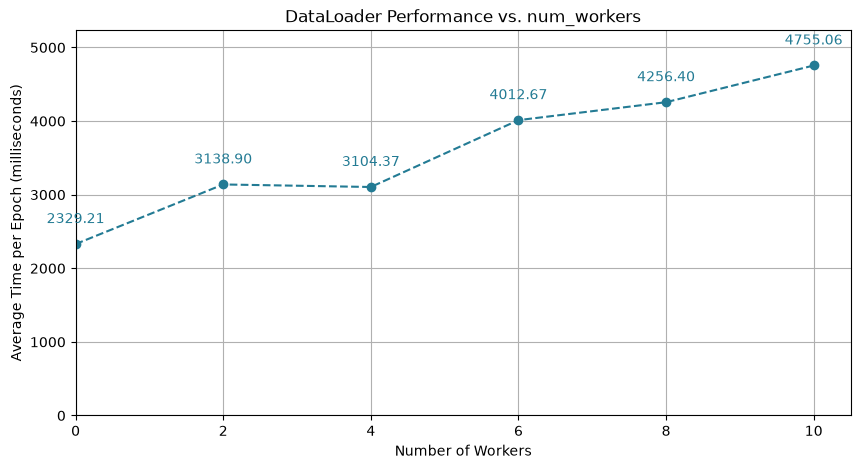


No valid loader results to plot.
Results for experiment 'batch_size_times' not found. Running experiment.
Executing experiment 'batch_size_times'...
------ Testing Batch Size = 16 ---


Overall Progress: 100%|██████████| 5/5 [00:21<00:00,  4.22s/it]



  Epoch 1/5 | Time: 4.05 seconds (warm-up)
  Epoch 2/5 | Time: 3.95 seconds (warm-up)
  Epoch 3/5 | Time: 4.76 seconds 
  Epoch 4/5 | Time: 4.07 seconds 
  Epoch 5/5 | Time: 4.24 seconds 

Average execution time (avg of last 3): 4.36 seconds

------ Testing Batch Size = 32 ---


Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.19s/it]



  Epoch 1/5 | Time: 4.09 seconds (warm-up)
  Epoch 2/5 | Time: 4.15 seconds (warm-up)
  Epoch 3/5 | Time: 4.20 seconds 
  Epoch 4/5 | Time: 4.14 seconds 
  Epoch 5/5 | Time: 4.33 seconds 

Average execution time (avg of last 3): 4.23 seconds

------ Testing Batch Size = 64 ---


Overall Progress: 100%|██████████| 5/5 [00:22<00:00,  4.46s/it]


... (3 outputs left out)

Overall Progress: 100%|██████████| 5/5 [00:29<00:00,  5.82s/it]



  Epoch 1/5 | Time: 5.85 seconds (warm-up)
  Epoch 2/5 | Time: 5.45 seconds (warm-up)
  Epoch 3/5 | Time: 5.83 seconds 
  Epoch 4/5 | Time: 6.39 seconds 
  Epoch 5/5 | Time: 5.55 seconds 

Average execution time (avg of last 3): 5.93 seconds

------ Testing Batch Size = 512 ---


Overall Progress: 100%|██████████| 5/5 [00:28<00:00,  5.80s/it]



  Epoch 1/5 | Time: 5.80 seconds (warm-up)
  Epoch 2/5 | Time: 5.40 seconds (warm-up)
  Epoch 3/5 | Time: 5.45 seconds 
  Epoch 4/5 | Time: 5.67 seconds 
  Epoch 5/5 | Time: 6.66 seconds 

Average execution time (avg of last 3): 5.93 seconds

Results for 'batch_size_times' saved to ./checkpoint_experiments/batch_size_times.json 


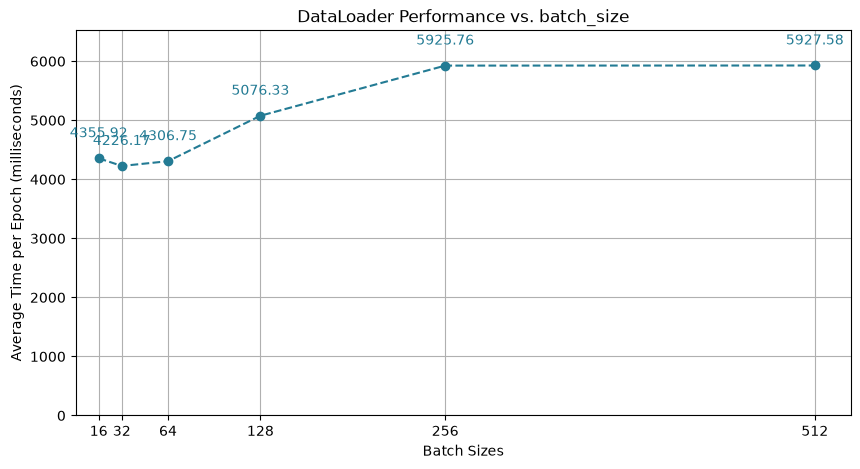

Results for experiment 'pin_memory_times' not found. Running experiment.
Executing experiment 'pin_memory_times'...


Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.12s/it]



  Epoch 1/5 | Time: 3.89 seconds (warm-up)
  Epoch 2/5 | Time: 4.23 seconds (warm-up)
  Epoch 3/5 | Time: 4.25 seconds 
  Epoch 4/5 | Time: 4.23 seconds 
  Epoch 5/5 | Time: 3.96 seconds 

Average execution time (avg of last 3): 4.15 seconds



Overall Progress: 100%|██████████| 5/5 [00:21<00:00,  4.21s/it]



  Epoch 1/5 | Time: 4.26 seconds (warm-up)
  Epoch 2/5 | Time: 4.83 seconds (warm-up)
  Epoch 3/5 | Time: 4.02 seconds 
  Epoch 4/5 | Time: 3.97 seconds 
  Epoch 5/5 | Time: 3.98 seconds 

Average execution time (avg of last 3): 3.99 seconds

Results for 'pin_memory_times' saved to ./checkpoint_experiments/pin_memory_times.json 


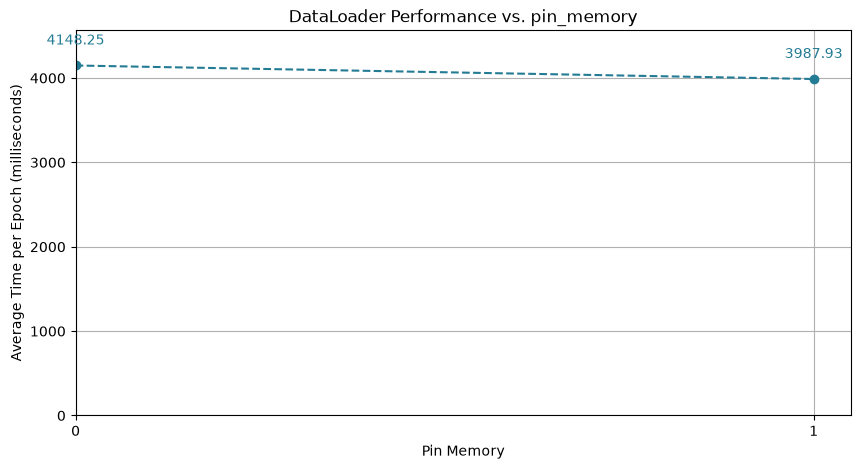

Results for experiment 'prefetch_factor_times' not found. Running experiment.
Executing experiment 'prefetch_factor_times'...


Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.16s/it]



  Epoch 1/5 | Time: 4.08 seconds (warm-up)
  Epoch 2/5 | Time: 4.02 seconds (warm-up)
  Epoch 3/5 | Time: 4.09 seconds 
  Epoch 4/5 | Time: 4.01 seconds 
  Epoch 5/5 | Time: 4.60 seconds 

Average execution time (avg of last 3): 4.23 seconds



Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.06s/it]



  Epoch 1/5 | Time: 4.15 seconds (warm-up)
  Epoch 2/5 | Time: 4.00 seconds (warm-up)
  Epoch 3/5 | Time: 3.98 seconds 
  Epoch 4/5 | Time: 4.09 seconds 
  Epoch 5/5 | Time: 4.07 seconds 

Average execution time (avg of last 3): 4.05 seconds



Overall Progress: 100%|██████████| 5/5 [00:21<00:00,  4.23s/it]


... (3 outputs left out)

Overall Progress: 100%|██████████| 5/5 [00:20<00:00,  4.18s/it]



  Epoch 1/5 | Time: 4.95 seconds (warm-up)
  Epoch 2/5 | Time: 4.06 seconds (warm-up)
  Epoch 3/5 | Time: 3.91 seconds 
  Epoch 4/5 | Time: 3.97 seconds 
  Epoch 5/5 | Time: 3.98 seconds 

Average execution time (avg of last 3): 3.95 seconds



Overall Progress: 100%|██████████| 5/5 [00:21<00:00,  4.30s/it]



  Epoch 1/5 | Time: 4.23 seconds (warm-up)
  Epoch 2/5 | Time: 4.18 seconds (warm-up)
  Epoch 3/5 | Time: 4.06 seconds 
  Epoch 4/5 | Time: 4.85 seconds 
  Epoch 5/5 | Time: 4.19 seconds 

Average execution time (avg of last 3): 4.37 seconds

Results for 'prefetch_factor_times' saved to ./checkpoint_experiments/prefetch_factor_times.json 


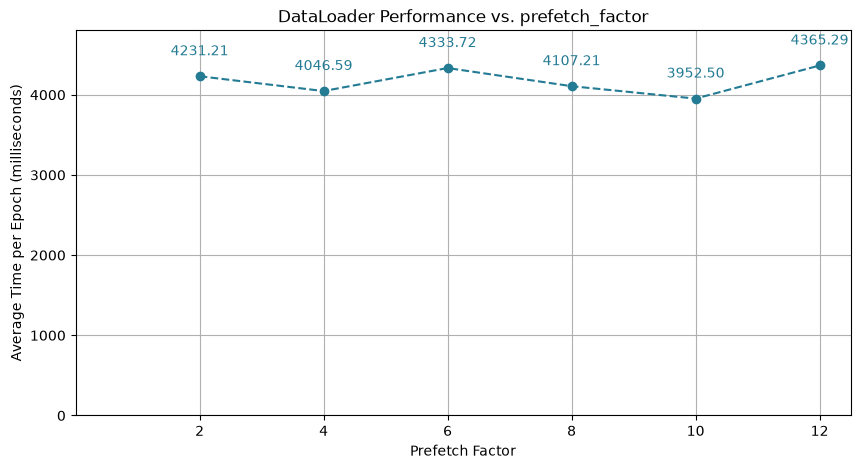

In [10]:
workers_to_test = [0, 2, 4, 6, 8, 10]
batch_sizes_to_test = [16, 32, 64, 128, 256, 512]
pin_memory_settings = [False, True]
prefetch_factors_to_test = [2, 4, 6, 8, 10, 12]

worker_times = run_experiment(
    experiment_name='worker_times', 
    experiment_fcn=experiment_with_workers, 
    cases=workers_to_test, 
    trainset=training_data, 
    device=device,
    rerun=False
)

plot_performance_summary(
    worker_times, 
    title="DataLoader Performance vs. num_workers", 
    xlabel="Number of Workers", 
    ylabel="Average Time per Epoch (milliseconds)"
)

loaders_to_compare = {
    f"{nw} Workers": DataLoader(training_data, batch_size=32, num_workers=nw) 
    for nw in workers_to_test
}
visualize_dataloader_efficiency(loaders_to_compare, device)

del loaders_to_compare
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

batch_size_times = run_experiment(
    experiment_name="batch_size_times", 
    experiment_fcn=experiment_batch_sizes,
    cases=batch_sizes_to_test,
    trainset=training_data,
    device=device,
    rerun=False
)

plot_performance_summary(
    batch_size_times, 
    title="DataLoader Performance vs. batch_size", 
    xlabel="Batch Sizes", 
    ylabel="Average Time per Epoch (milliseconds)"
)
pin_memory_times = run_experiment(
    experiment_name="pin_memory_times",
    experiment_fcn=experiment_pin_memory,
    cases=pin_memory_settings,
    trainset=training_data, 
    device=device,
    rerun=False
)

plot_performance_summary(
    pin_memory_times, 
    title="DataLoader Performance vs. pin_memory", 
    xlabel="Pin Memory", 
    ylabel="Average Time per Epoch (milliseconds)"
)

prefetch_factor_times = run_experiment(
    experiment_name="prefetch_factor_times", 
    experiment_fcn=experiment_with_prefetch_factor,
    cases=prefetch_factors_to_test,
    trainset=training_data, 
    device=device,
    rerun=False
)

plot_performance_summary(
    prefetch_factor_times, 
    title="DataLoader Performance vs. prefetch_factor", 
    xlabel="Prefetch Factor", 
    ylabel="Average Time per Epoch (milliseconds)"
)

### Análise

Pode ser observado que os parâmetros mais eficiêntes para os recursos da máquina são:

- prefech_factor=10
- batch_size=32
- workers=4
- pin_memory=True

### DataLoaders

In [11]:
BATCH = 32

train_loader = DataLoader(training_data,   batch_size=BATCH, shuffle=True,  num_workers=4,prefetch_factor=10,pin_memory=True)
val_loader   = DataLoader(validating_data, batch_size=BATCH, shuffle=False, num_workers=4,prefetch_factor=10,pin_memory=True)
test_loader  = DataLoader(testing_data,    batch_size=BATCH, shuffle=False, num_workers=4,prefetch_factor=10,pin_memory=True)

### Arquitetura do modelo

In [12]:
model = resnet50(weights=ResNet50_Weights.DEFAULT)

for p in model.parameters():
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features,2)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.fc.parameters(), lr=5e-5)
squeduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, "min")

In [13]:
EPOCHS = 50
PATIENCE = 5

history = {"train":[], "val":[]}
best_val_loss = float("inf")
best_state = None
epochs_without_imporvement = 0


for epoch in range(EPOCHS):
    train_m = training_epoch(model=model,loader= train_loader,train=True,device=device,criterion=criterion,optimizer=optimizer)
    val_m = training_epoch(model=model,loader= val_loader,train=False,device=device,criterion=criterion,optimizer=optimizer)
    
    history["train"].append(train_m)
    history["val"].append(val_m)
    
    print(f"época {epoch+1:2d} | treino loss {train_m['loss']:.3f} acc {train_m['accuracy']:.3f} "
        f"| val loss {val_m['loss']:.3f} acc {val_m['accuracy']:.3f} "
        f"prec {val_m['precision']:.3f} rec {val_m['recall']:.3f}")
    
    if val_m['loss'] < best_val_loss:
        best_val_loss = val_m['loss']
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "melhor_modelo.pt")
        epochs_without_imporvement = 0
    else:
        epochs_without_imporvement += 1
        
        if epochs_without_imporvement >= PATIENCE:
            print(f"Early stopping na época {epoch+1} (melhor val loss: {best_val_loss:.3f})")
            break
        
model.load_state_dict(best_state)
        

época  1 | treino loss 0.663 acc 0.654 | val loss 0.655 acc 0.694 prec 0.594 rec 0.905
época  2 | treino loss 0.654 acc 0.684 | val loss 0.652 acc 0.653 prec 0.571 rec 0.762
época  3 | treino loss 0.637 acc 0.706 | val loss 0.645 acc 0.673 prec 0.600 rec 0.714
época  4 | treino loss 0.630 acc 0.763 | val loss 0.640 acc 0.653 prec 0.600 rec 0.571
época  5 | treino loss 0.624 acc 0.759 | val loss 0.632 acc 0.714 prec 0.684 rec 0.619
época  6 | treino loss 0.622 acc 0.750 | val loss 0.629 acc 0.714 prec 0.684 rec 0.619
época  7 | treino loss 0.609 acc 0.798 | val loss 0.622 acc 0.694 prec 0.667 rec 0.571
época  8 | treino loss 0.597 acc 0.807 | val loss 0.614 acc 0.714 prec 0.684 rec 0.619
época  9 | treino loss 0.594 acc 0.794 | val loss 0.607 acc 0.816 prec 0.750 rec 0.857
época 10 | treino loss 0.587 acc 0.851 | val loss 0.599 acc 0.816 prec 0.750 rec 0.857
época 11 | treino loss 0.584 acc 0.864 | val loss 0.602 acc 0.816 prec 0.773 rec 0.810
época 12 | treino loss 0.576 acc 0.842 | va

<All keys matched successfully>

### Métricas

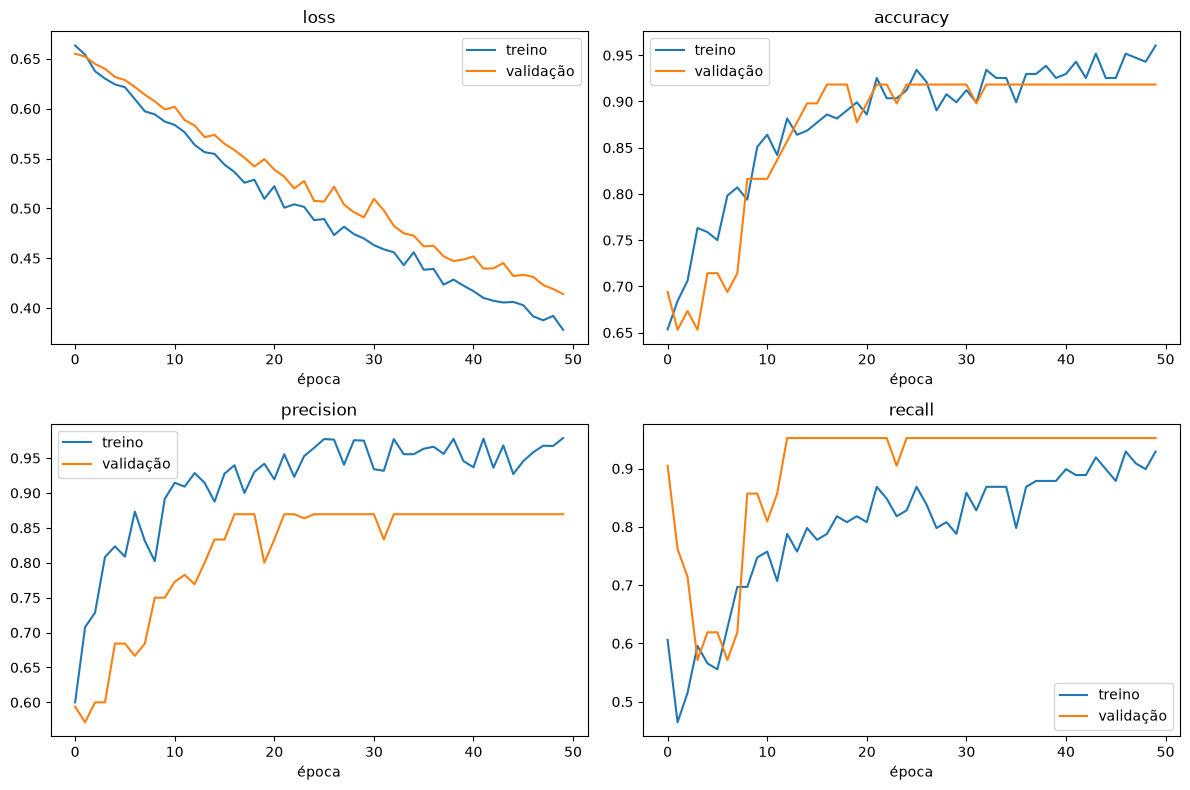

In [14]:
metrics = ["loss", "accuracy", "precision", "recall"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, m in zip(axes.flat, metrics):
    ax.plot([h[m] for h in history["train"]], label="treino")
    ax.plot([h[m] for h in history["val"]],   label="validação")
    ax.set_title(m)
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()


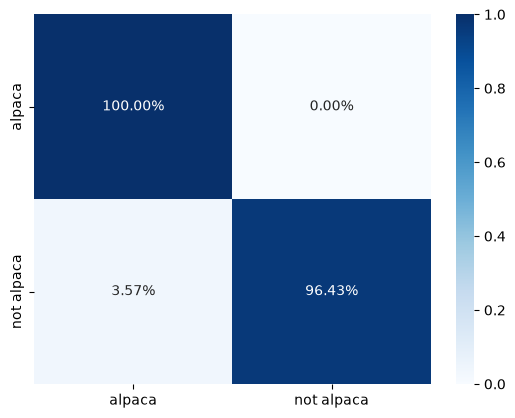

In [15]:
test_m = training_epoch(model=model,loader=test_loader,train=False, device=device,criterion=criterion,optimizer=optimizer)
classes = list(val_data.class_to_idx.keys())

cm = confusion_matrix(test_m['y_true'],test_m['y_pred'], normalize="true")

sns.heatmap(cm, annot=True, fmt='.2%', cmap="Blues",
                xticklabels=classes, yticklabels=classes)
ax.set(xlabel="Predito", ylabel="Real", title="Matriz de confusão")
plt.show()

In [17]:
print(classification_report(test_m["y_true"], test_m["y_pred"],target_names=val_data.class_to_idx.keys()))

              precision    recall  f1-score   support

      alpaca       0.96      1.00      0.98        22
  not alpaca       1.00      0.96      0.98        28

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



### Exportar em formato onnx

In [18]:
model.load_state_dict(best_state)   # garante que exporta o melhor modelo
model.eval()

example_inputs = (torch.randn(1, 3, 224, 224, device=device),)

onnx_program = torch.onnx.export(
    model,
    example_inputs,
    dynamo=True,
    input_names=["image"],
    output_names=["logits"],
    dynamic_shapes=({0: "batch"},),   # permite qualquer tamanho de batch, não só 1
)
onnx_program.save("modelo_alpaca.onnx")


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/home/orlandojunior/miniconda3/envs/huggingface/lib/python3.14/copyreg.py:104: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


In [20]:
onnx_inputs = [tensor.numpy(force=True) for tensor in example_inputs]
print(f"Input length: {len(onnx_inputs)}")
print(f"Sample input: {onnx_inputs}")

ort_session = ort.InferenceSession(
    "./modelo_alpaca.onnx", providers=["CPUExecutionProvider"]
)

onnxruntime_input = {input_arg.name: input_value for input_arg, input_value in zip(ort_session.get_inputs(), onnx_inputs)}

# ONNX Runtime returns a list of outputs
onnxruntime_outputs = ort_session.run(None, onnxruntime_input)[0]
onnxruntime_outputs 

Input length: 1
Sample input: [array([[[[-2.1873355 ,  0.3948202 ,  1.0862644 , ...,  0.23172171,
          -1.375558  , -0.23011892],
         [ 0.4857618 , -0.26563692,  1.109645  , ...,  1.5261347 ,
          -0.17145222,  0.02788448],
         [-0.3557192 ,  0.02145508, -1.1275288 , ..., -1.8601614 ,
           0.44910145, -0.25243628],
         ...,
         [-1.3875626 , -0.9765398 , -1.5097986 , ...,  2.0316792 ,
           0.8447409 , -1.2883542 ],
         [-0.05864831,  0.35004154,  1.7653569 , ...,  0.6618488 ,
          -0.24745947, -0.6173918 ],
         [ 0.6735399 ,  0.25226286, -2.1015294 , ...,  1.67306   ,
           1.7133108 ,  1.6273535 ]],

        [[ 1.7859904 ,  0.8546277 ,  0.27262464, ..., -1.3633958 ,
          -1.1251943 ,  0.15368564],
         [-0.4255062 , -0.4047252 , -2.8876579 , ..., -0.01953477,
          -0.12343822, -1.5134946 ],
         [ 2.3133283 ,  1.0697962 , -0.20808405, ...,  0.2194223 ,
           0.40982747, -2.2244155 ],
         ...,
   

array([[-0.4600283 ,  0.22648245]], dtype=float32)

In [21]:
sess = ort.InferenceSession("modelo_alpaca.onnx")
torch_outputs = model(*example_inputs).cpu()

assert len(torch_outputs) == len(onnxruntime_outputs)
for torch_output, onnxruntime_output in zip(torch_outputs, onnxruntime_outputs):
    torch.testing.assert_close(torch_output, torch.tensor(onnxruntime_output), rtol=1e-3, atol=1e-4)

print("PyTorch and ONNX Runtime output matched!")
print(f"Output length: {len(onnxruntime_outputs)}")
print(f"Sample output: {onnxruntime_outputs}")


PyTorch and ONNX Runtime output matched!
Output length: 1
Sample output: [[-0.4600283   0.22648245]]
